# TODO: дополнительные проверки данных и эксперименты

Черновик для отдельного разбора. Содержательная полезность опытов для тьютора ещё требует обсуждения. Основной EDA находится в `../EDA.ipynb`; этот ноутбук не входит в основной результат.

Здесь сохранены опыты с представлением формул, предсказанием первой метки КЭС, изменением оформления и подсчётом шаблонных семейств. Графики и метрики сохранены; исполнение читает локальные результаты. Частоты разметки относятся к 315 сохранённым / 312 включённым задачам, классификация условий — к банку из 1148 условий.

In [1]:
from pathlib import Path
import sys, json, csv, shutil
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image
root=next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/'scripts/build_checkpoint2.py').exists())
sys.path.insert(0,str(root/'scripts'))
ROOT=root
OUT=root/'notebooks/checkpoint-2/experimental/derived'
OUT.mkdir(parents=True,exist_ok=True)
for name in ['current-kc-family-summary.json','current-kc-family-frequency.csv','current-kc-family-tasks.csv']:
    source=root/'notebooks/checkpoint-2/derived'/name
    if source.exists(): shutil.copyfile(source,OUT/name)
def table(rows):
    rows=list(rows)
    if not rows:return
    def clean(x):return str(x).replace('|',' / ').replace('\n',' ')
    keys=list(rows[0]);display(Markdown('| '+' | '.join(keys)+' |\n| '+' | '.join(['---']*len(keys))+' |\n'+'\n'.join('| '+' | '.join(clean(r[k]) for k in keys)+' |' for r in rows)))
def chart(name):
    plt.tight_layout();plt.savefig(OUT/(name+'.png'),dpi=150,bbox_inches='tight');plt.close()
    display(Image(filename=str(OUT/(name+'.png'))))

## Дополнительные опыты

Основные показатели разметки и семейства упражнений используют текущие **315 задач / 312 включённых**. Доменный анализ и вспомогательный ML baseline используют весь неизменившийся банк **1148 условий**: добавление разборов не меняет его train/dev/test и не требует переобучения.

### 1. Корпус и границы сравнения

Пять слоёв: редакторские 50, исторические независимые 50, первое дополнение 100, 50 Sol и следующее дополнение 65. Источники различаются составом и процедурами. Редакторские назначения не являются независимым аудитом, агентные аудиты — экспертным эталоном. `321FCD` исключена общей политикой как partial; исторические исключения сохранены. Для `F416AF` используется исправленная попытка после обратной связи, для `9c96c5` — техническая коррекция порядка ссылок. Новые 65 ещё не слиты в общую ветку.

In [2]:
from checkpoint2_extensions import load_saved, DIRS, FIGURES
ROOT = root
extension, extension_hashes = load_saved(ROOT)
import csv
from IPython.display import Image, Markdown, display

def ext_json(key, name):
    return json.loads((ROOT / DIRS[key] / name).read_text(encoding='utf-8'))

def ext_rows(key, name):
    with (ROOT / DIRS[key] / name).open(encoding='utf-8-sig', newline='') as f:
        return list(csv.DictReader(f))

def ext_table(rows, keys):
    def clean(v): return str(v).replace('|',' / ').replace('\n',' ')
    display(Markdown('| '+' | '.join(keys)+' |\n| '+' | '.join(['---']*len(keys))+' |\n'+'\n'.join('| '+' | '.join(clean(r.get(k,'')) for k in keys)+' |' for r in rows)))

def ext_figure(key, name):
    display(Image(filename=str(ROOT / DIRS[key] / name)))

manifest315 = json.loads((ROOT/'data/annotation/analyses/2026-11-10-saved-data-refresh-v1/manifest.json').read_text(encoding='utf-8'))
ext_table([{'слой':'Группа '+str(i+1),'разборов':v,'в частотах':sum(r['included'] for r in manifest315 if r['origin']==k)} for i,(k,v) in enumerate(Counter(r['origin'] for r in manifest315).items())], ['слой','разборов','в частотах'])

| слой | разборов | в частотах |
| --- | --- | --- |
| Группа 1 | 50 | 49 |
| Группа 2 | 50 | 49 |
| Группа 3 | 50 | 50 |
| Группа 4 | 100 | 99 |
| Группа 5 | 65 | 65 |

### 2. Домен: текст, формулы и рисунки

Банк — смешанный NLP/CV-источник: 1148 условий, 4067 узлов MathML, 443 локальных assets; 286 задач содержат рисунки, 859 — MathML. Модель ниже не видит содержание рисунков. Официальных ответов, решений и надёжного года отдельной задачи нет; 315 текущих разборов — слабая предварительная разметка для исследования, а не ground truth правильности.

Первая сохранённая метка КЭС даёт 26 операционных классов для routing; все метки — 29 кодов и 1707 назначений. У 409 задач несколько меток. Первая метка не означает единственную тему, а КЭС не равен KC. График сравнивает эти два знаменателя.

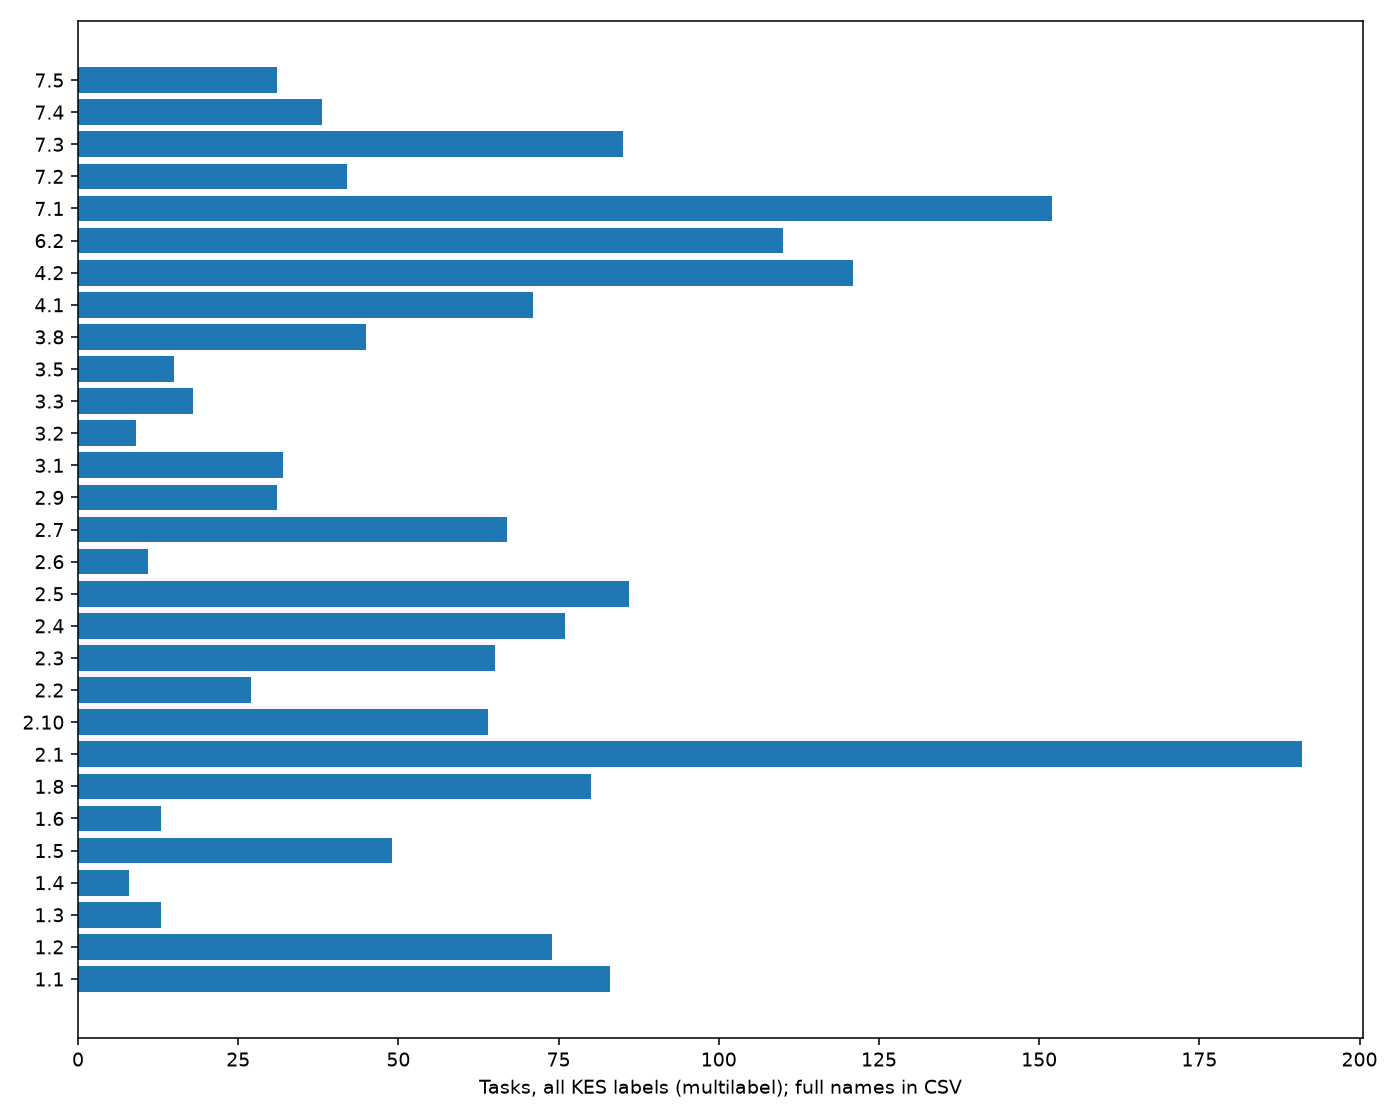

In [3]:
ext_figure('quality','01-label-balance.png')

Проверены файлы изображений, длины, символы, MathML и шаблонные повторы. Нулевой/битый asset не обнаружен; есть один символ замены и 80 задач с zero-width символами. Диагностика HTML-парсера сама по себе не равна повреждению: MathML/HTML требует контекстной проверки. Выброс по длине или числу формул — кандидат на просмотр, а не ошибка и не измеренная трудность для ученика. Порог MAD для изображений вырождается из-за нулевой медианы, поэтому не используется как содержательный классификатор.

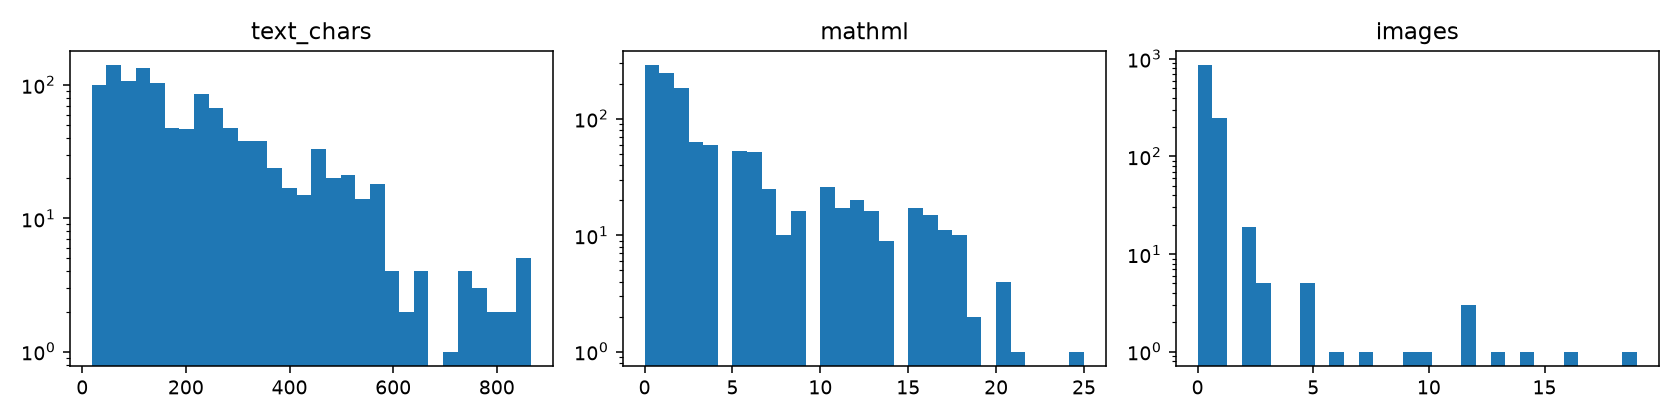

| metric | value | task_id | source_url | candidate_only |
| --- | --- | --- | --- | --- |
| text_chars | 866 | 6e44FB | https://ege.fipi.ru/bank/index.php?proj=AC437B34557F88EA4115D2F374B0A07B&qid=6e44FB | True |
| text_chars | 866 | e8AA65 | https://ege.fipi.ru/bank/index.php?proj=AC437B34557F88EA4115D2F374B0A07B&qid=e8AA65 | True |
| text_chars | 852 | A87FAB | https://ege.fipi.ru/bank/index.php?proj=AC437B34557F88EA4115D2F374B0A07B&qid=A87FAB | True |
| text_chars | 848 | 40BED3 | https://ege.fipi.ru/bank/index.php?proj=AC437B34557F88EA4115D2F374B0A07B&qid=40BED3 | True |
| text_chars | 842 | 6FF25e | https://ege.fipi.ru/bank/index.php?proj=AC437B34557F88EA4115D2F374B0A07B&qid=6FF25e | True |

In [4]:
ext_figure('quality','02-structure.png')
ext_table(ext_rows('quality','outlier-top5.csv')[:5], list(ext_rows('quality','outlier-top5.csv')[0])[:5])

Обычное извлечение текста теряет отношения. Например, в `4CBD4E` дробь $1/7$ становится `1 7`, а степень $(1/7)^{x+4}$ — последовательностью символов без границ основания и показателя. Структурные токены `MFRAC` и `MSUP` сохраняют тип и вложенность узлов. Это техническая сохранность записи, не понимание математики. Ниже — сохранённый конкретный пример и сравнение модальностей.

| task_id | tag | flattened | semantic |
| --- | --- | --- | --- |
| 4CBD4E | mfrac |  1 7  | MFRAC MN 1 END_MN MN 7 END_MN END_MFRAC |

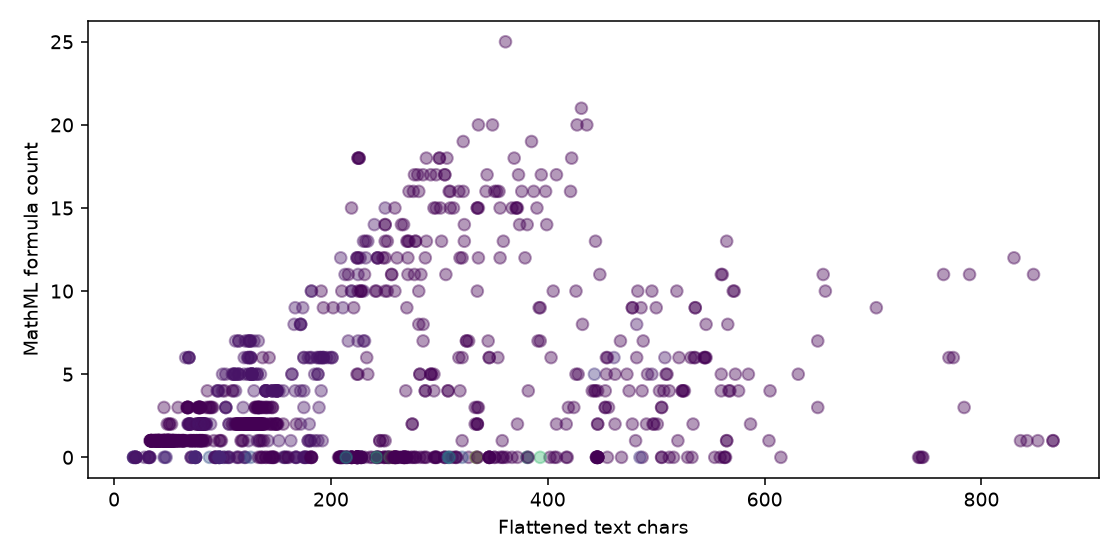

In [5]:
example_flat = ext_json('quality','flatten-examples.json')[1]
ext_table([example_flat], ['task_id','tag','flattened','semantic'])
ext_figure('quality','03-multimodal.png')

### 3. Вспомогательный routing baseline

Цель — предсказать первую метку КЭС по условию. Это маршрутизация к разделу банка, а не решение задачи, оценка LLM, диагностика ученика или качество тьютора. Реализованы NumPy majority, multinomial Naive Bayes и TF–IDF cosine 1NN; DL не обучался. Из входа исключены ID, URL, метаданные КЭС, ответы, решения и аудит. Словарь и веса строятся на train; test не подбирает модель.

Group split удерживает числовые шаблоны целиком: train/dev/test = 789/176/183, test — 154 группы. Группировка по всему банку — заранее заданная transductive проверка целостности, не обучение на test-метках. В test есть классы с единичной поддержкой; интервалы bootstrap считаются по группам. Random split имеет 21 test-задачу с шаблоном из train; group — ни одной. На этом seed завышение random-качества **не показано**.

Первичный baseline заранее зафиксирован как semantic NB: accuracy 0.6776, macro-F1 0.4308, top-3 0.8634. Структурное представление не улучшает все модели: NB хуже plain NB (0.7377 / 0.4804), semantic 1NN лучше plain 1NN (0.8251 / 0.6886 против 0.7705 / 0.6307). Random semantic NB имеет ту же accuracy, random semantic 1NN — немного ниже group. Полезен сам анализ зависимости от представления, а не обещание неизбежного роста.

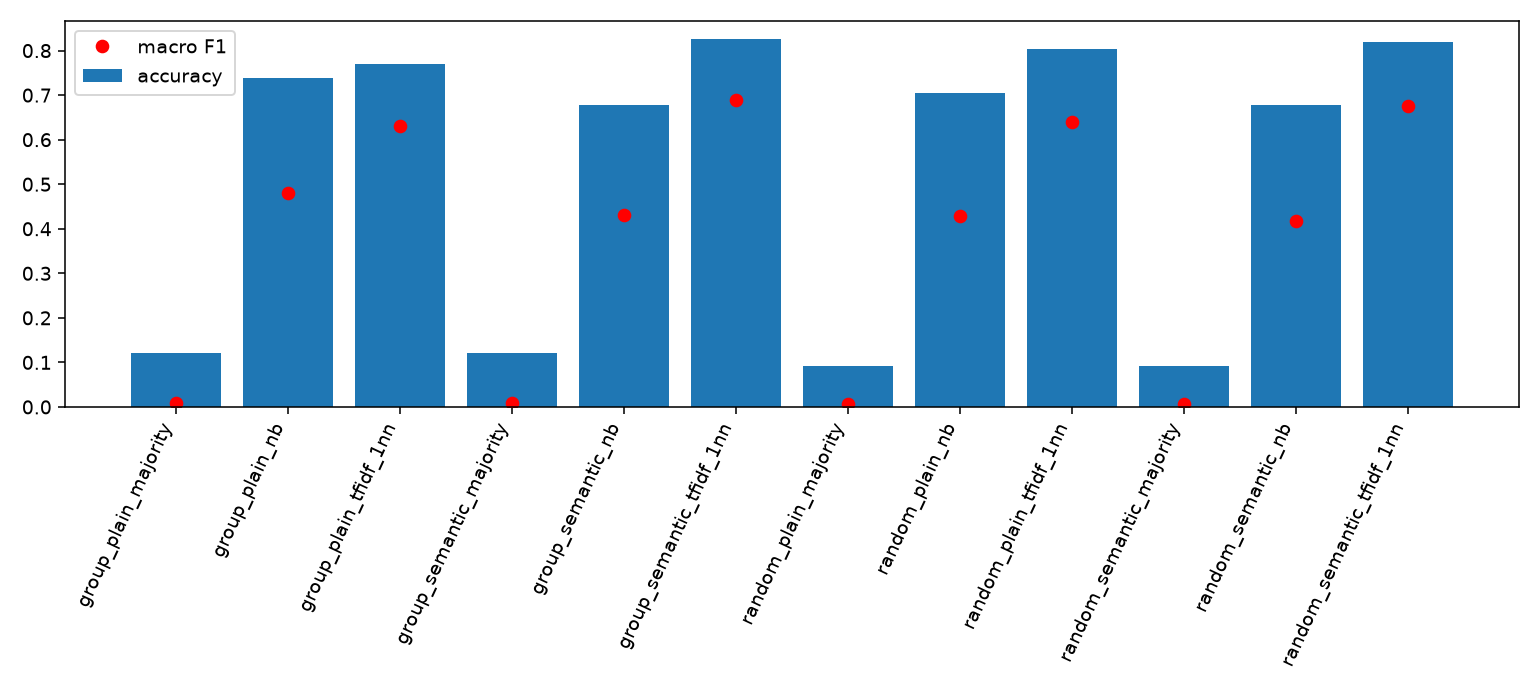

| model | accuracy | macro_f1 | top3_accuracy |
| --- | --- | --- | --- |
| group_semantic_majority | 0.12021857923497267 | 0.00825515947467167 | 0.366120218579235 |
| group_semantic_nb | 0.6775956284153005 | 0.4308219199727511 | 0.8633879781420765 |
| group_semantic_tfidf_1nn | 0.825136612021858 | 0.6886012116129927 | 0.9562841530054644 |
| random_semantic_majority | 0.09289617486338798 | 0.006538461538461539 | 0.34972677595628415 |
| random_semantic_nb | 0.6775956284153005 | 0.4169881711872559 | 0.8797814207650273 |
| random_semantic_tfidf_1nn | 0.819672131147541 | 0.6762997261398797 | 0.9672131147540983 |

| метрика | нижняя | верхняя |
| --- | --- | --- |
| accuracy | 0.597824568860821 | 0.7525831113170393 |
| macro_f1 | 0.35292737332433705 | 0.47871395117123905 |
| top3_accuracy | 0.8011687599681021 | 0.9197914438502673 |

In [6]:
ext_figure('baseline','01-model-comparison.png')
metrics11 = [r for r in extension['baseline']['metrics'] if r['partition']=='test' and 'semantic' in r['model']]
ext_table(metrics11, ['model','accuracy','macro_f1','top3_accuracy'])
ext_table([{'метрика':k,'нижняя':v[0],'верхняя':v[1]} for k,v in extension['baseline']['group_bootstrap_ci95'].items()], ['метрика','нижняя','верхняя'])

NB объясним через вклад токенов в разность log-вероятностей классов. Частые тематические слова помогают, но пунктуация и оформление также несут корреляции. Ниже — характерные признаки и две ошибки с локальными вкладами; ошибкой считается несовпадение с операционной первой КЭС, а не доказанная математическая ошибочность условия.

In [7]:
features11=ext_rows('baseline','distinctive-features.csv')
ext_table([r for r in features11 if r['rank']=='1'][:8], ['class_label','feature','distinctive_log_probability'])
errors11=[r for r in ext_json('baseline','explanations.json') if not r['correct']][:2]
assert len(errors11)==2, 'Two saved baseline error explanations required'
for err in errors11:
    display(Markdown('**'+err['task_id']+'**: первая КЭС '+err['actual']+' → предсказано '+err['predicted']))
    ext_table(err['features'][:4], ['token','count','margin'])

| class_label | feature | distinctive_log_probability |
| --- | --- | --- |
| 1.1 | чисел | 4.015938352881714 |
| 1.2 | - | 4.0853513655826905 |
| 1.3 | mroot | 3.2683220559696 |
| 1.4 | выражения | 2.125468705083926 |
| 1.5 | sin | 3.4115873034423556 |
| 1.6 | log | 2.375303002287958 |
| 2.1 | км | 3.2735515418783123 |
| 2.10 |  /  | 3.5071549363829337 |

**0BD320**: первая КЭС 2.4 → предсказано 2.3

| token | count | margin |
| --- | --- | --- |
| end_mtext | 9 | -5.3020666673559695 |
| mtext | 9 | -5.3020666673559695 |
| mo | 9 | 3.803068781094442 |
| end_mo | 9 | 3.803068781094442 |

**0C4928**: первая КЭС 2.3 → предсказано 2.1

| token | count | margin |
| --- | --- | --- |
| в | 5 | 21.609735918192822 |
| , | 9 | 13.030285936538545 |
| / | 2 | 7.19272945465093 |
| end_mstyle | 9 | 7.076636206478493 |

### 4. Проверенная аугментация оформления

Детерминированная смена пробелов, эквивалентных Unicode-символов и HTML-обёрток проверена по сигнатурам математической структуры, чисел/операторов и assets: 1148/1148 проходят. Semantic token invariance — 100%; взвешенные counts после дублирования совпадают точно. Поэтому прироста качества здесь нет: это полезная отрицательная проверка и основание нормализовать оформление. Устойчивость постоянного majority сама по себе не свидетельствует о полезности. Варианты не увеличивают число независимых задач; замена чисел и геометрические трансформации этим опытом не проверены.

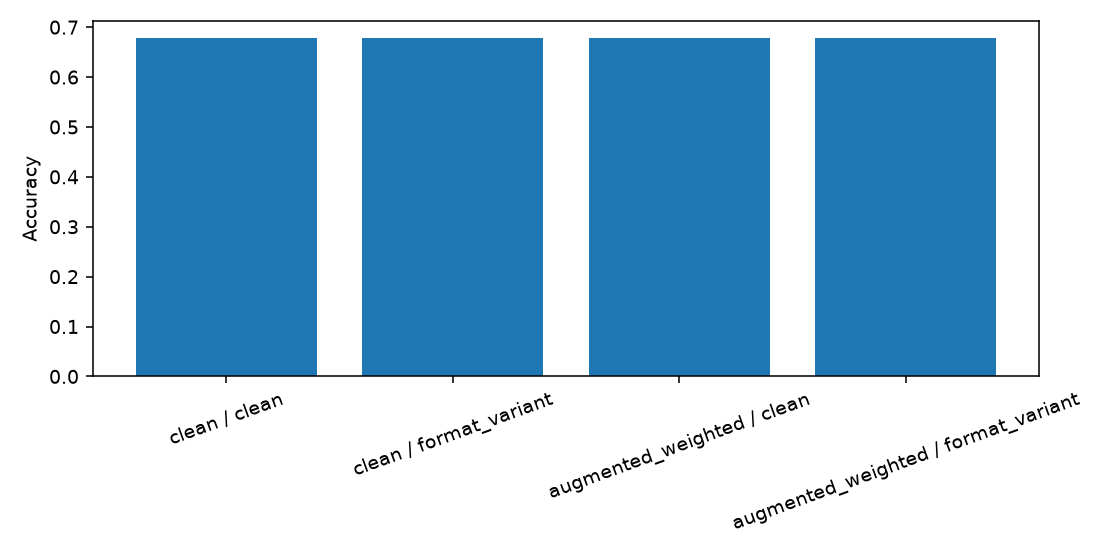

In [8]:
ext_figure('baseline','04-format-robustness.png')

### 5. KC и независимые семейства упражнений

Частота задач с KC может завышать запас разнообразной практики: числовые варианты одного шаблона не дают независимых контекстов. График и таблица ниже заново рассчитаны для всех 312 включённых задач. Семейство определяется прежним правилом маскирования чисел с сохранением структуры и SHA рисунков. Число семейств — технический признак разнообразия, а не число независимых методов или доказанный перенос освоения. Каталог фиксирован и предварителен; новые кандидаты между задачами не консолидированы.

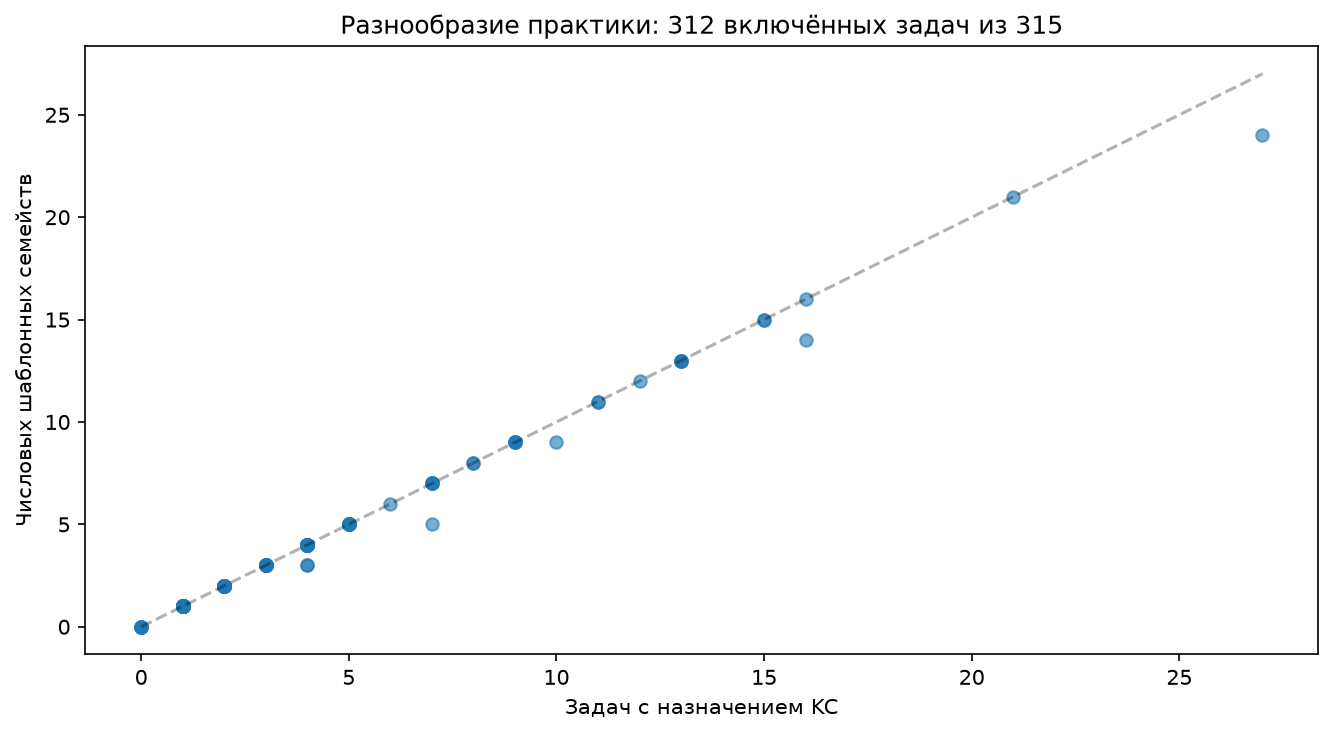

| Задач | Семейств | Определений каталога | 0 | 1 | 2 | >=3 |
| --- | --- | --- | --- | --- | --- | --- |
| 312 | 302 | 144 | 5 | 45 | 23 | 71 |

**Линейное уравнение:** 27 задач, 24 семейств. Нулевая/малая поддержка узла требует проверки разнообразия упражнений, а не вывода об освоении.

In [9]:
family_current=json.loads((OUT/'current-kc-family-summary.json').read_text(encoding='utf-8'))
with (OUT/'current-kc-family-frequency.csv').open(encoding='utf-8-sig') as f:
    family_rows=list(csv.DictReader(f))
fig,ax=plt.subplots(figsize=(9,5))
ax.scatter([int(r['task_frequency']) for r in family_rows],[int(r['family_frequency']) for r in family_rows],alpha=.6)
upper=max(int(r['task_frequency']) for r in family_rows)
ax.plot([0,upper],[0,upper],'k--',alpha=.3)
ax.set(xlabel='Задач с назначением KC',ylabel='Числовых шаблонных семейств',title='Разнообразие практики: 312 включённых задач из 315')
chart('11-current-task-vs-family')
table([{'Задач':family_current['included_tasks'],'Семейств':family_current['families'],'Определений каталога':family_current['catalog_nodes'],**family_current['support_bins']}])
linear_family=family_current['linear_equation']
display(Markdown('**Линейное уравнение:** '+str(linear_family['task_frequency'])+' задач, '+str(linear_family['family_frequency'])+' семейств. Нулевая/малая поддержка узла требует проверки разнообразия упражнений, а не вывода об освоении.'))

### 6. Что выполнено и как применять в тьюторе

| Критерий | Исполненный результат | Граница |
|---|---|---|
| Специфика домена | Текст, MathML, рисунки; конкретная потеря дроби/степени | Структура не равна математическому пониманию |
| Баланс классов | Все КЭС против первой метки; редкие классы сохранены | 26 классов routing не равны навыкам |
| Качество, объём, выбросы | 1148 условий, 315 разборов (312 включённых), технические проверки и кандидаты аномалий | Нет официальных ответов и экспертного эталона |
| Простой ML baseline | Majority, NB, TF–IDF 1NN; random/group; признаки, ошибки, bootstrap | Вспомогательная маршрутизация, не DL и не оценка тьютора |
| Аугментация | Проверены инварианты и предсказания форматного преобразования | Прироста и новых независимых задач нет |
| Предметная модель | KC × задачи × шаблонные семейства | Не prerequisites и не адаптивная рекомендация |

В будущем прототипе результаты задают требования к сохранению формул и рисунков, подсказке раздела для нового условия и отбору упражнений с разными контекстами. Результаты не обновляют профиль ученика: для этого нужны наблюдаемые самостоятельные попытки, различение помощи и решения, проверка математической корректности и учебный эксперимент.

Полные сохранённые отчёты: [250 разборов](../../../data/annotation/analyses/2026-11-09-fipi-checkpoint-250-v1/report.md), [доменное качество](../../../data/annotation/analyses/2026-11-09-domain-quality-v1/report.md), [routing baseline](../../../data/annotation/analyses/2026-11-09-routing-baseline-v1/report.md), [KC и семейства](../../../data/annotation/analyses/2026-11-09-kc-families-v1/report.md). Их provenance фиксируют происхождение и хеши; исполнение главы проверяет SHA сохранённых артефактов и независимые счётчики manifest, не вызывает collectors.

Текущие частоты семейств: [таблица](derived/current-kc-family-frequency.csv), [ID и семейства 312 задач](derived/current-kc-family-tasks.csv), [сводка](derived/current-kc-family-summary.json). Ссылки на прежние 250 выше сохраняют историю; основные графики используют текущий набор.